# 3.7 Spatially aware concept discovery

This notebook visualizes the outputs produced by the local spatially aware concept-discovery pipeline. It reads the completed model artifacts and does not retrain the models. Figures are exported as 300-dpi PNG and vector SVG files.

**Interpretation boundary.** The discovered clusters are exploratory, unreviewed concepts learned from weak seller-title supervision. They are not validated fashion taxonomies or ground-truth visual attributes.

In [1]:
from pathlib import Path
import json, math, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

ROOT = Path.cwd()
if not (ROOT / 'fashion_vn').exists():
    ROOT = ROOT.parent
MODEL_ROOT = ROOT / 'models' / 'local_resnet18_set_v2'
CACHE_ROOT = ROOT / 'outputs' / 'cache_resnet18'
MANIFEST = ROOT / 'outputs' / 'prepared_set_v2' / 'manifest.jsonl'
FIG_DIR = ROOT / 'outputs' / 'figures' / 'spatial_concepts'
FIG_DIR.mkdir(parents=True, exist_ok=True)
CATEGORY = 'top'  # detailed case study; change and rerun for another trained category

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'figure.titlesize': 16})
COLORS = {'blue':'#386CB0', 'green':'#59A14F', 'orange':'#E68600',
          'purple':'#8E63B5', 'red':'#CC4F4F', 'gray':'#929292'}

def savefig(fig, stem):
    fig.savefig(FIG_DIR / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor='white')
    fig.savefig(FIG_DIR / f'{stem}.svg', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

run = json.loads((MODEL_ROOT / 'run_summary.json').read_text(encoding='utf-8'))
trained = {k:v for k,v in run.items() if v.get('status') == 'trained_unvalidated'}
skipped = {k:v for k,v in run.items() if v.get('status') != 'trained_unvalidated'}
rows = [json.loads(line) for line in MANIFEST.read_text(encoding='utf-8').splitlines()]
print(f'Trained categories: {list(trained)}')
print(f'Skipped categories: {skipped}')
print(f'Figures: {FIG_DIR}')

Trained categories: ['top', 'dress', 'pants', 'skirt', 'jacket', 'bag', 'hat', 'set']
Skipped categories: {}
Figures: D:\RESEARCH\THESIS 2\fashion_vn\outputs\figures\spatial_concepts


## 3.7.1 Completed-run overview

,category,train_products,validation_products,vocabulary,discovered_concepts,trained_heads,epochs,best_validation_loss
0,top,1967,240,594,30,29,7,0.1582
1,dress,1815,198,490,30,30,8,0.1659
2,pants,1069,139,382,30,28,9,0.1449
3,skirt,676,94,253,30,26,8,0.1538
4,jacket,1110,134,382,30,29,9,0.1449
5,bag,413,60,187,30,22,13,0.2015
6,hat,342,36,174,30,18,12,0.1320
7,set,480,68,241,30,26,10,0.1513


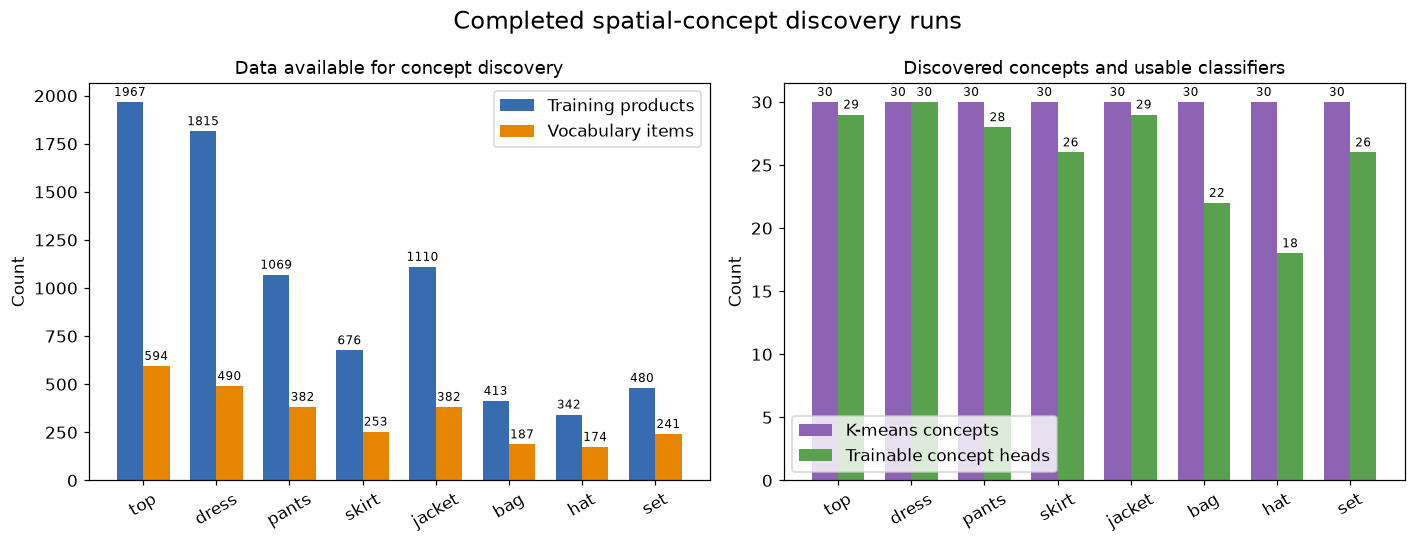

In [2]:
summary = pd.DataFrame([{
    'category': cat, 'train_products': s['train'], 'validation_products': s['val'],
    'vocabulary': s['vocabulary'], 'discovered_concepts': s['concepts'],
    'trained_heads': s['heads'], 'epochs': s['epochs_run'],
    'best_validation_loss': s['best_val_weak_ranking_loss']} for cat,s in trained.items()])
summary.to_csv(FIG_DIR / '3_7_1_category_summary.csv', index=False, encoding='utf-8-sig')
display(summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(summary)); width = .36
axes[0].bar(x-width/2, summary.train_products, width, label='Training products', color=COLORS['blue'])
axes[0].bar(x+width/2, summary.vocabulary, width, label='Vocabulary items', color=COLORS['orange'])
axes[0].set_xticks(x, summary.category, rotation=30); axes[0].set_ylabel('Count')
axes[0].set_title('Data available for concept discovery'); axes[0].legend()
for container in axes[0].containers: axes[0].bar_label(container, fontsize=8, padding=2)
axes[1].bar(x-width/2, summary.discovered_concepts, width, label='K-means concepts', color=COLORS['purple'])
axes[1].bar(x+width/2, summary.trained_heads, width, label='Trainable concept heads', color=COLORS['green'])
axes[1].set_xticks(x, summary.category, rotation=30); axes[1].set_ylabel('Count')
axes[1].set_title('Discovered concepts and usable classifiers'); axes[1].legend()
for container in axes[1].containers: axes[1].bar_label(container, fontsize=8, padding=2)
fig.suptitle('Completed spatial-concept discovery runs')
fig.tight_layout(); savefig(fig, 'figure_3_7_1_completed_runs')

## 3.7.2 Visual-semantic embedding convergence

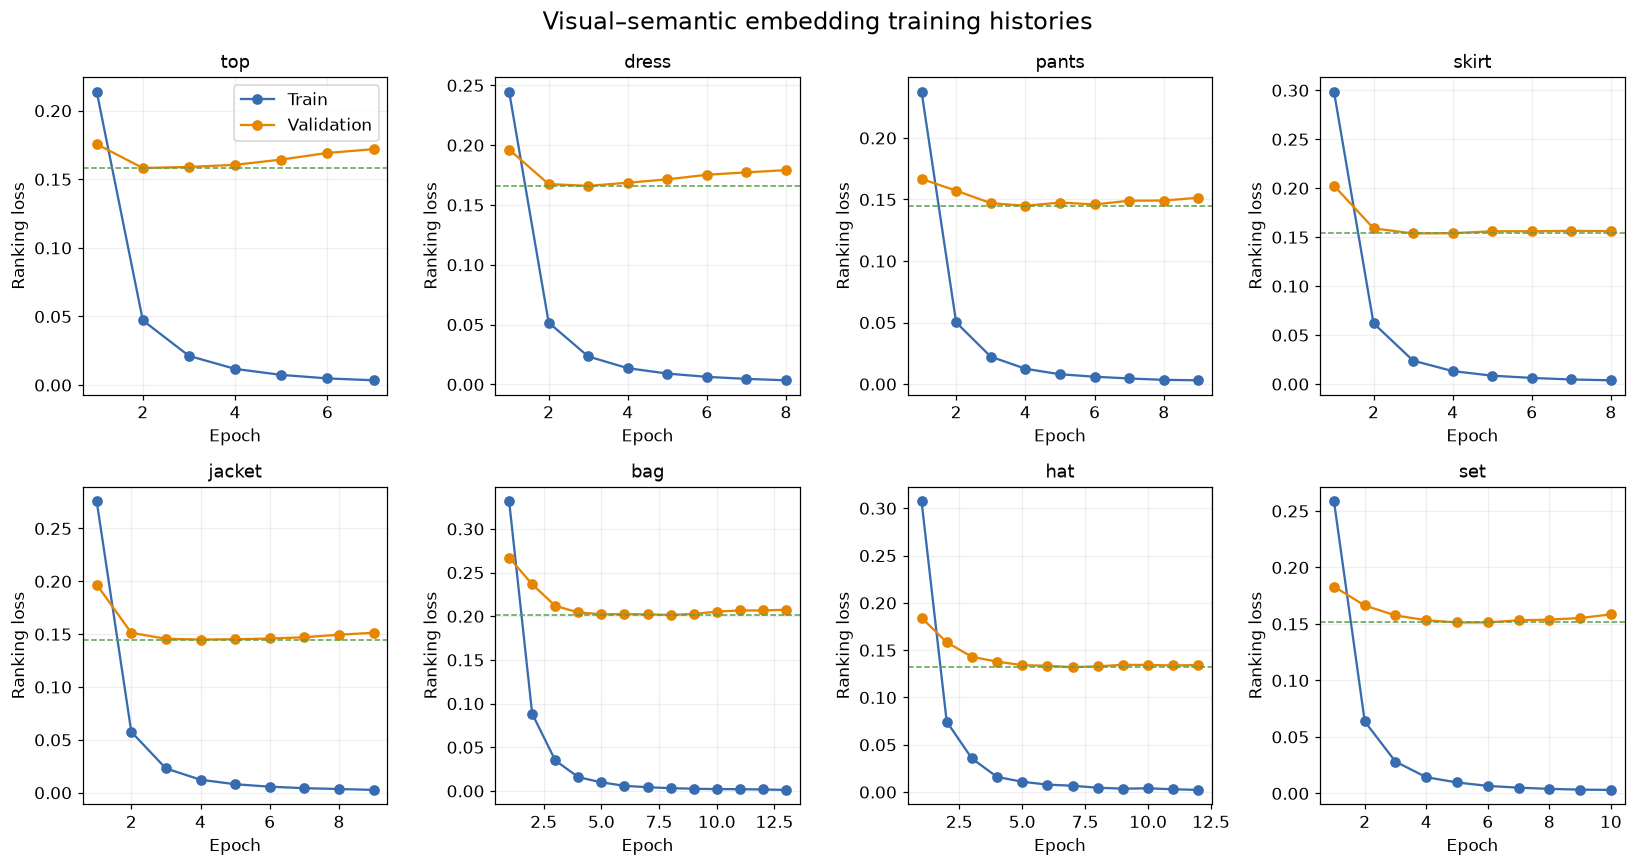

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8), sharex=False)
axes = axes.ravel()
for ax, (cat, status) in zip(axes, trained.items()):
    history = json.loads((MODEL_ROOT/cat/'training_history.json').read_text())
    ep = [h['epoch'] for h in history]
    ax.plot(ep, [h['train_loss'] for h in history], marker='o', label='Train', color=COLORS['blue'])
    ax.plot(ep, [h['val_weak_ranking_loss'] for h in history], marker='o', label='Validation', color=COLORS['orange'])
    ax.axhline(status['best_val_weak_ranking_loss'], color=COLORS['green'], ls='--', lw=1)
    ax.set_title(cat); ax.set_xlabel('Epoch'); ax.set_ylabel('Ranking loss'); ax.grid(alpha=.2)
axes[0].legend()
for ax in axes[len(trained):]: ax.axis('off')
fig.suptitle('Visual–semantic embedding training histories')
fig.tight_layout(); savefig(fig, 'figure_3_7_2_vse_training_histories')

## 3.7.3 Joint spatial–semantic concept space

Each vocabulary item is represented by the concatenation of a normalized spatial activation pattern and a normalized 64-dimensional Word2vec vector. PCA is used only for two-dimensional visualization; K-means was fitted in the original joint space.

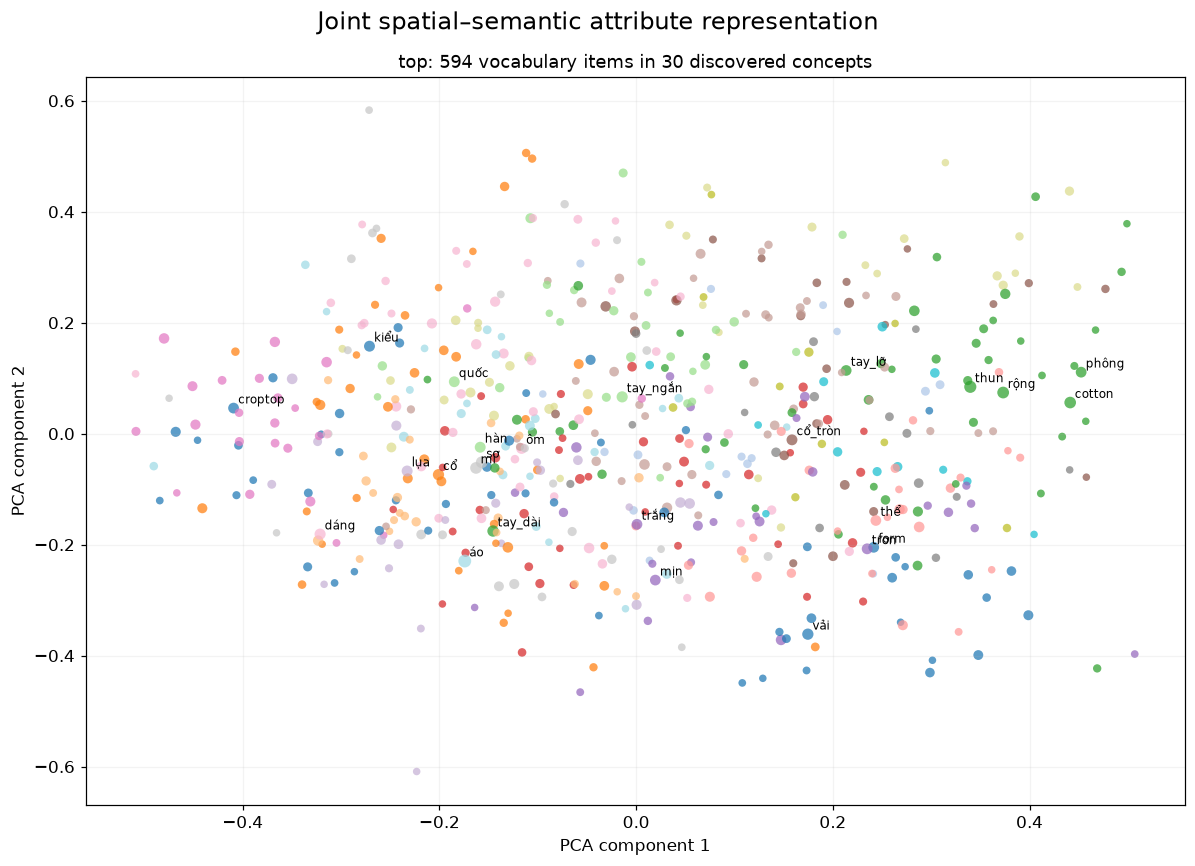

In [4]:
data = np.load(MODEL_ROOT/CATEGORY/'attribute_representations.npz', allow_pickle=False)
vocab = data['vocab'].astype(str); spatial = data['spatial']; semantic = data['semantic']
counts = data['counts']; clusters = data['clusters']
joint = np.concatenate([normalize(spatial), normalize(semantic)], axis=1)
xy = PCA(n_components=2, random_state=42).fit_transform(joint)

fig, ax = plt.subplots(figsize=(11, 8))
sc = ax.scatter(xy[:,0], xy[:,1], c=clusters, cmap='tab20', s=10+8*np.log1p(counts),
                alpha=.72, linewidths=0)
for i in np.argsort(counts)[-25:]:
    ax.annotate(vocab[i], xy[i], fontsize=8, xytext=(3,3), textcoords='offset points')
ax.set_xlabel('PCA component 1'); ax.set_ylabel('PCA component 2')
ax.set_title(f'{CATEGORY}: {len(vocab):,} vocabulary items in {len(set(clusters))} discovered concepts')
ax.grid(alpha=.15)
fig.suptitle('Joint spatial–semantic attribute representation')
fig.tight_layout(); savefig(fig, 'figure_3_7_3_joint_concept_space')

## 3.7.4 Cluster composition and size

,concept_id,size,training_mentions,representative_terms
7,7,34,2560,"thun, rộng, cotton, phông, tay_lỡ, in"
29,29,15,2169,"áo, xanh, đỏ, hoạ, xanh_lá, nhật"
22,22,15,1201,"sơ, mi, linen, đũi, cúc, tàu"
8,8,29,1037,"tay_ngắn, hàn, quốc, dành, hình, bản"
0,0,29,945,"vải, form, thấm, hút, túi, chống"
11,11,28,928,"thể, thao, chiều, tập, lạnh, gym"
14,14,21,921,"lụa, hai_dây, ba, lỗ, không, ngực"
19,19,17,863,"dáng, ôm, body, tôn, sọc, tăm"
1,1,26,855,"kiểu, croptop, thêu, tay_phồng, top, ngắn"
4,4,21,824,"cổ, tay, dây, eo, kèm, vai"


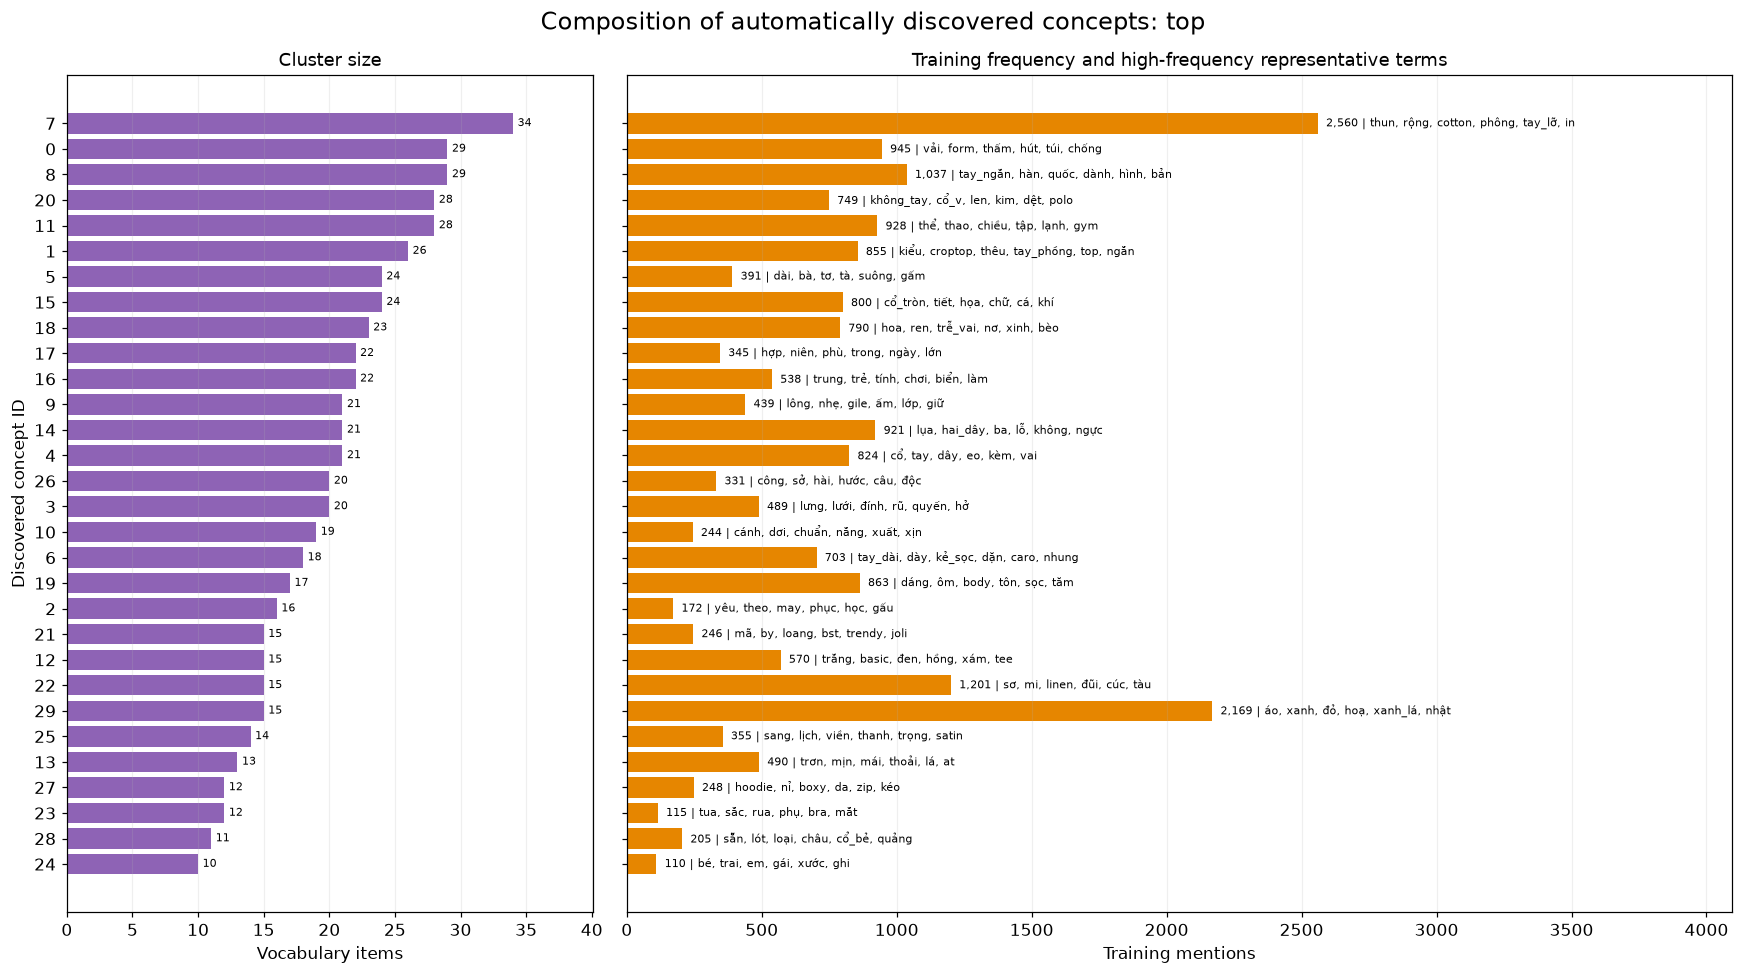

In [5]:
concept_rows = []
for cid in sorted(set(clusters)):
    ids = np.where(clusters == cid)[0]
    top_ids = ids[np.argsort(counts[ids])[::-1][:6]]
    concept_rows.append({'concept_id': int(cid), 'size': len(ids),
                         'training_mentions': int(counts[ids].sum()),
                         'representative_terms': ', '.join(vocab[top_ids])})
concept_df = pd.DataFrame(concept_rows).sort_values(['training_mentions','size'], ascending=False)
concept_df.to_csv(FIG_DIR / f'3_7_4_{CATEGORY}_concept_composition.csv', index=False, encoding='utf-8-sig')
display(concept_df.head(15))

ordered = concept_df.sort_values('size')
fig, (ax_size, ax_mentions) = plt.subplots(1, 2, figsize=(16, 9), sharey=True,
                                           gridspec_kw={'width_ratios': [1, 2.1]})
labels = ordered.concept_id.astype(str)
size_bars = ax_size.barh(labels, ordered['size'], color=COLORS['purple'])
ax_size.set_xlabel('Vocabulary items'); ax_size.set_ylabel('Discovered concept ID')
ax_size.set_title('Cluster size')
for bar, value in zip(size_bars, ordered['size']):
    ax_size.text(bar.get_width()+.35, bar.get_y()+bar.get_height()/2,
                 f'{int(value)}', va='center', fontsize=7)
ax_size.set_xlim(0, ordered['size'].max()*1.18); ax_size.grid(axis='x', alpha=.2)
mention_bars = ax_mentions.barh(labels, ordered['training_mentions'], color=COLORS['orange'])
ax_mentions.set_xlabel('Training mentions')
ax_mentions.set_title('Training frequency and high-frequency representative terms')
max_mentions = ordered['training_mentions'].max()
for bar, (_, r) in zip(mention_bars, ordered.iterrows()):
    terms = textwrap.shorten(r.representative_terms, width=55, placeholder='…')
    label = f"{int(r.training_mentions):,} | {terms}"
    ax_mentions.text(bar.get_width()+max_mentions*.012, bar.get_y()+bar.get_height()/2,
                     label, va='center', fontsize=7)
ax_mentions.set_xlim(0, max_mentions*1.6); ax_mentions.grid(axis='x', alpha=.2)
fig.suptitle(f'Composition of automatically discovered concepts: {CATEGORY}')
fig.tight_layout(); savefig(fig, 'figure_3_7_4_concept_composition')

## 3.7.5 Mean spatial activation maps

The stored AAM for a term is the activation map averaged over its positive training titles. The maps show learned spatial tendencies on the 7×7 ResNet feature grid; they do not establish causal localization or segmentation accuracy.

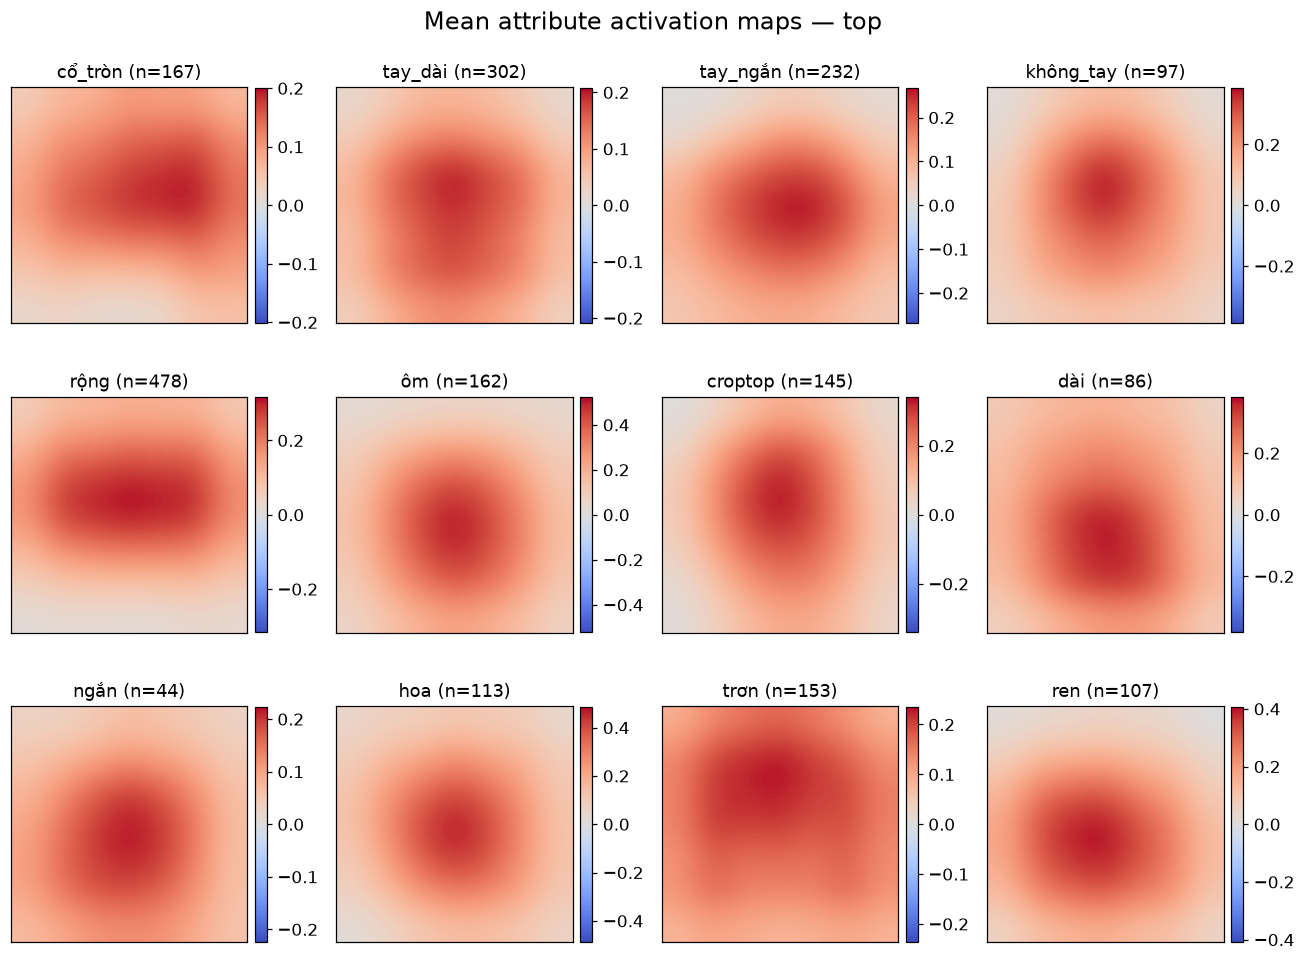

In [6]:
preferred = ['cổ_tròn','tay_dài','tay_ngắn','không_tay','rộng','ôm','croptop','dài','ngắn','hoa','trơn','ren']
chosen = [t for t in preferred if t in set(vocab)]
if len(chosen) < 12:
    chosen += [vocab[i] for i in np.argsort(counts)[::-1] if vocab[i] not in chosen][:12-len(chosen)]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, term in zip(axes.ravel(), chosen[:12]):
    i = int(np.where(vocab == term)[0][0]); aam = spatial[i].reshape(7, 7)
    lim = max(abs(float(aam.min())), abs(float(aam.max())), 1e-8)
    im = ax.imshow(aam, cmap='coolwarm', norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), interpolation='bicubic')
    ax.set_title(f'{term} (n={counts[i]:,})'); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
fig.suptitle(f'Mean attribute activation maps — {CATEGORY}')
fig.tight_layout(); savefig(fig, 'figure_3_7_5_mean_attribute_activation_maps')

## 3.7.6 Image-level activation examples

For selected frequent terms, this cell chooses one training image whose title contains the term and overlays the corresponding image-level activation map. Selection is deterministic and illustrative, not an accuracy evaluation.

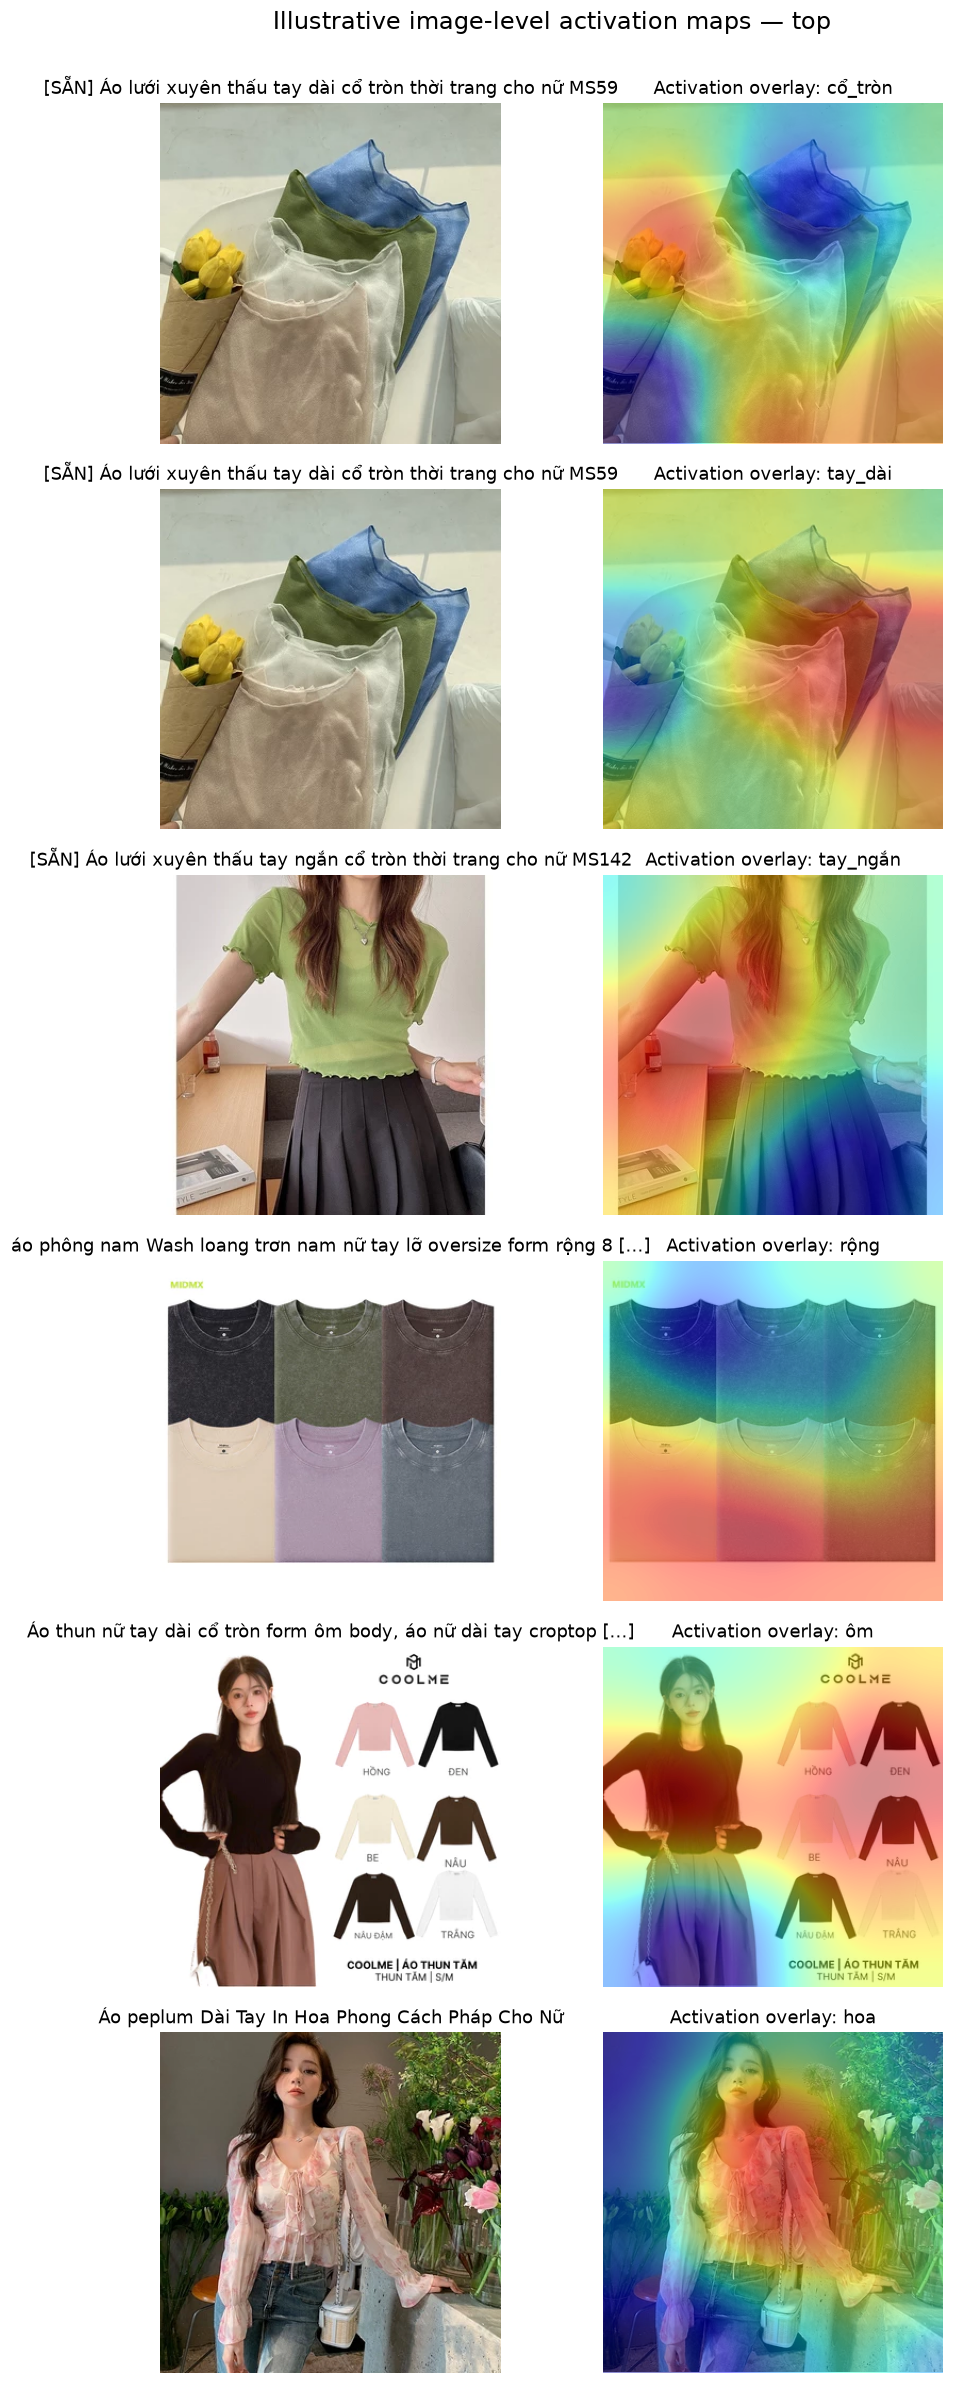

In [7]:
import torch
ck = torch.load(MODEL_ROOT/CATEGORY/'vse.pt', map_location='cpu', weights_only=True)
word = torch.nn.functional.normalize(ck['state_dict']['word_embedding.weight'], dim=1)
effective = (word @ ck['state_dict']['image_projection.weight']).numpy()
eligible = [r for r in rows if r['category'] == CATEGORY and r['split'] == 'train' and r['image_status'] == 'ok']
example_terms = [t for t in ['cổ_tròn','tay_dài','tay_ngắn','rộng','ôm','hoa'] if t in set(vocab)]
examples = []
for term in example_terms:
    candidates = [r for r in eligible if term in r['tokens'] and (CACHE_ROOT/f"{r['image_sha256']}.npy").exists()]
    if candidates: examples.append((term, sorted(candidates, key=lambda r:r['product_id'])[0]))

fig, axes = plt.subplots(len(examples), 2, figsize=(9, 3.6*len(examples)))
if len(examples) == 1: axes = np.array([axes])
for row_axes, (term, r) in zip(axes, examples):
    image = ImageOps.exif_transpose(Image.open(r['image_path'])).convert('RGB')
    fmap = np.load(CACHE_ROOT/f"{r['image_sha256']}.npy").astype(np.float32)
    i = int(np.where(vocab == term)[0][0]); heat = (effective[i] @ fmap.reshape(fmap.shape[0], -1)).reshape(7, 7)
    row_axes[0].imshow(image); row_axes[0].axis('off'); row_axes[0].set_title(textwrap.shorten(r['title_raw'], 70))
    row_axes[1].imshow(image); row_axes[1].imshow(heat, cmap='jet', alpha=.45, extent=(0,image.width,image.height,0), interpolation='bicubic')
    row_axes[1].axis('off'); row_axes[1].set_title(f'Activation overlay: {term}')
fig.suptitle(f'Illustrative image-level activation maps — {CATEGORY}', y=1.002)
fig.tight_layout(); savefig(fig, 'figure_3_7_6_image_level_activation_examples')

## 3.7.7 Spatial-pattern similarity among frequent terms

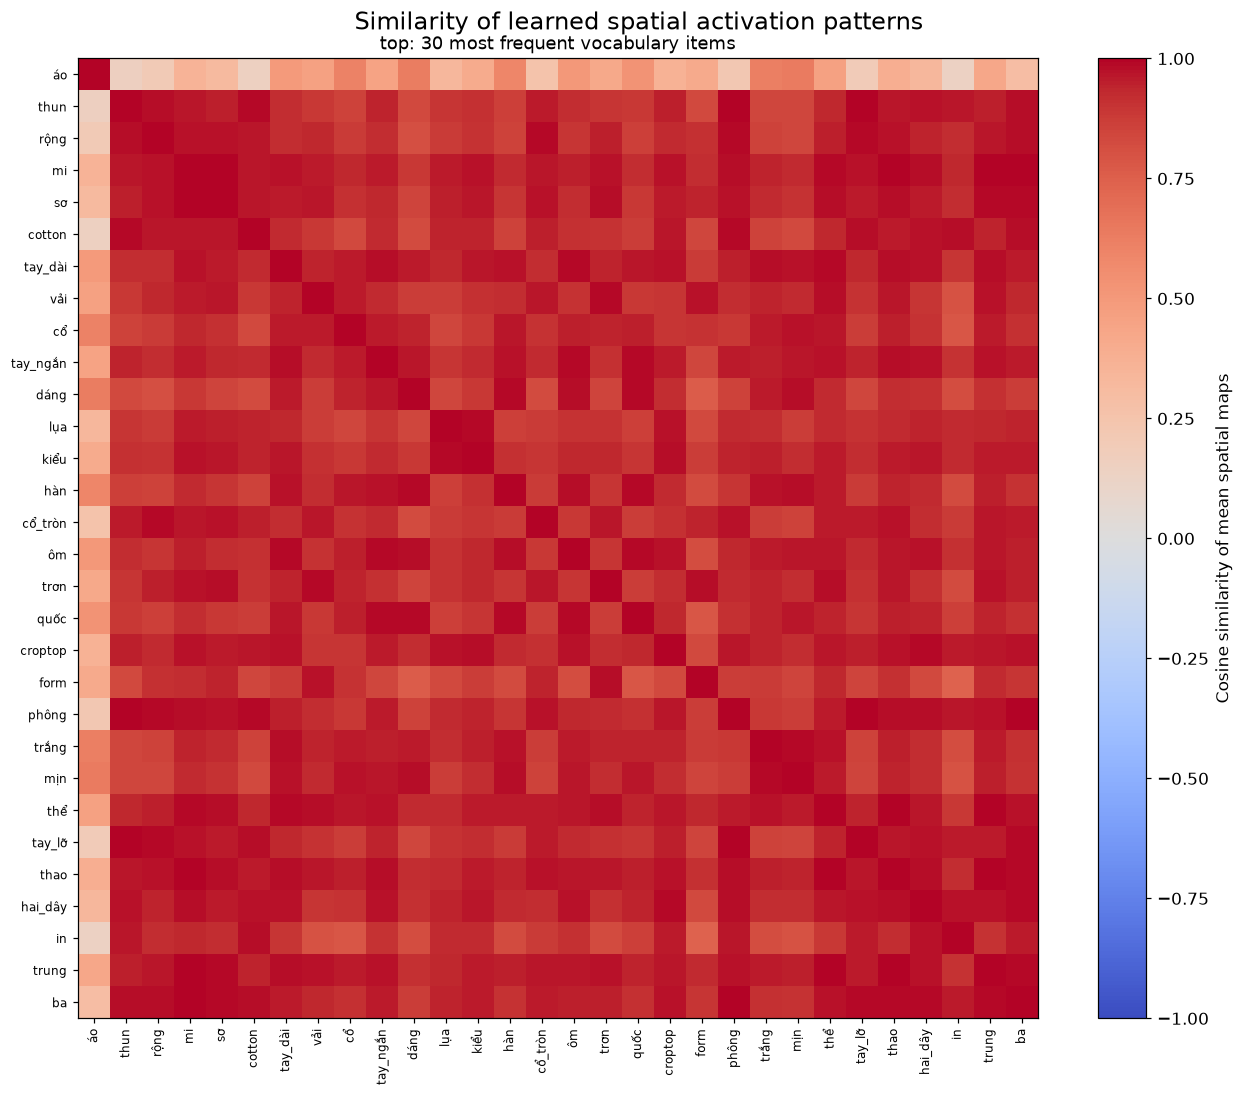

In [8]:
ids = np.argsort(counts)[::-1][:30]
S = normalize(spatial[ids]) @ normalize(spatial[ids]).T
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(S, cmap='vlag' if 'vlag' in plt.colormaps() else 'coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(ids)), vocab[ids], rotation=90, fontsize=8)
ax.set_yticks(range(len(ids)), vocab[ids], fontsize=8)
fig.colorbar(im, ax=ax, label='Cosine similarity of mean spatial maps')
ax.set_title(f'{CATEGORY}: 30 most frequent vocabulary items')
fig.suptitle('Similarity of learned spatial activation patterns')
fig.tight_layout(); savefig(fig, 'figure_3_7_7_spatial_similarity')

## Report-ready synthesis and exported files

In [9]:
total_train = int(summary.train_products.sum()); total_vocab = int(summary.vocabulary.sum())
print('REPORT-READY SYNTHESIS')
print(f"Spatially aware concept discovery completed for {len(trained)} product categories, using {total_train:,} category-specific training instances in total. Each category produced 30 K-means clusters, while the number of trainable concept heads ranged from {summary.trained_heads.min()} to {summary.trained_heads.max()}. The largest category, {CATEGORY}, contained {trained[CATEGORY]['train']:,} training products and {trained[CATEGORY]['vocabulary']:,} retained vocabulary items. Its attribute representation combined a 49-dimensional spatial activation pattern from the 7×7 ResNet18 grid with a 64-dimensional Word2vec semantic vector. The clusters and activation maps remain exploratory because their supervision originated from noisy seller titles and no independent gold concept grouping or localization annotation was used.")
print('\nGenerated files:')
for p in sorted(FIG_DIR.iterdir()): print(' -', p.relative_to(ROOT))

REPORT-READY SYNTHESIS
Spatially aware concept discovery completed for 8 product categories, using 7,872 category-specific training instances in total. Each category produced 30 K-means clusters, while the number of trainable concept heads ranged from 18 to 30. The largest category, top, contained 1,967 training products and 594 retained vocabulary items. Its attribute representation combined a 49-dimensional spatial activation pattern from the 7×7 ResNet18 grid with a 64-dimensional Word2vec semantic vector. The clusters and activation maps remain exploratory because their supervision originated from noisy seller titles and no independent gold concept grouping or localization annotation was used.

Generated files:
 - outputs\figures\spatial_concepts\3_7_1_category_summary.csv
 - outputs\figures\spatial_concepts\3_7_4_top_concept_composition.csv
 - outputs\figures\spatial_concepts\figure_3_7_1_completed_runs.png
 - outputs\figures\spatial_concepts\figure_3_7_1_completed_runs.svg
 - out